In [1]:
import os
import gc
import re
import string
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import keras_hub
import matplotlib.pyplot as plt

from datasets import load_dataset, Dataset
from transformers import AutoTokenizer
from collections import Counter

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("KerasHub:", keras_hub.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2
KerasHub: 0.26.0


In [2]:
SEED = 42

keras.utils.set_random_seed(SEED)

PRESET = "bert_base_en_uncased"

MAX_LENGTH = 384
STRIDE = 128

EPOCHS = 2

PER_REPLICA_BATCH_SIZE = 4
LEARNING_RATE = 2e-5

DROPOUT = 0.1

print("Configuration loaded.")

Configuration loaded.


In [3]:
dataset = load_dataset("rajpurkar/squad_v2")

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()

print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))

print("\nTraining answerability:")
print(train_df["answers"].apply(
    lambda x: len(x["text"]) > 0
).value_counts())

print("\nValidation answerability:")
print(val_df["answers"].apply(
    lambda x: len(x["text"]) > 0
).value_counts())

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

squad_v2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

squad_v2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

squad_v2/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.35MB            

squad_v2/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

Training examples: 130319
Validation examples: 11873

Training answerability:
answers
True     86821
False    43498
Name: count, dtype: int64

Validation answerability:
answers
False    5945
True     5928
Name: count, dtype: int64


In [4]:
tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased",
    use_fast=True
)

print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model length:", tokenizer.model_max_length)
print("CLS token:", tokenizer.cls_token)
print("SEP token:", tokenizer.sep_token)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Vocabulary size: 30522
Maximum model length: 512
CLS token: [CLS]
SEP token: [SEP]


In [5]:
def preprocess_batch(examples):

    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        max_length=MAX_LENGTH,
        truncation="only_second",
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length"
    )

    sample_mapping = tokenized.pop(
        "overflow_to_sample_mapping"
    )

    offset_mapping = tokenized.pop(
        "offset_mapping"
    )

    start_positions = []
    end_positions = []

    for feature_idx, offsets in enumerate(offset_mapping):

        sample_idx = sample_mapping[feature_idx]

        answers = examples["answers"][sample_idx]

        cls_index = tokenized["input_ids"][feature_idx].index(
            tokenizer.cls_token_id
        )

        sequence_ids = tokenized.sequence_ids(feature_idx)

        # Unanswerable question
        if len(answers["text"]) == 0:

            start_positions.append(cls_index)
            end_positions.append(cls_index)

            continue

        start_char = answers["answer_start"][0]

        end_char = (
            start_char + len(answers["text"][0])
        )

        # Identify context tokens only
        context_indices = [
            idx
            for idx, sequence_id in enumerate(sequence_ids)
            if sequence_id == 1
        ]

        if not context_indices:

            start_positions.append(cls_index)
            end_positions.append(cls_index)

            continue

        token_start = context_indices[0]
        token_end = context_indices[-1]

        # Answer does not fit inside this window
        if (
            offsets[token_start][0] > start_char
            or offsets[token_end][1] < end_char
        ):

            start_positions.append(cls_index)
            end_positions.append(cls_index)

            continue

        # Find start token
        while (
            token_start <= token_end
            and offsets[token_start][0] <= start_char
        ):
            token_start += 1

        start_position = token_start - 1

        # Find end token
        while (
            token_end >= start_position
            and offsets[token_end][1] >= end_char
        ):
            token_end -= 1

        end_position = token_end + 1

        start_positions.append(start_position)
        end_positions.append(end_position)

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions

    return tokenized

In [6]:
train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df,
    preserve_index=False
)

train_features = train_dataset.map(
    preprocess_batch,
    batched=True,
    batch_size=500,
    remove_columns=train_dataset.column_names,
    desc="Preparing training features"
)

val_features = val_dataset.map(
    preprocess_batch,
    batched=True,
    batch_size=500,
    remove_columns=val_dataset.column_names,
    desc="Preparing validation features"
)

print("\nTraining features:", len(train_features))
print("Validation features:", len(val_features))

print("Input length:", len(train_features[0]["input_ids"]))

Preparing training features:   0%|          | 0/130319 [00:00<?, ? examples/s]

Preparing validation features:   0%|          | 0/11873 [00:00<?, ? examples/s]


Training features: 131754
Validation features: 12134
Input length: 384


In [7]:
kh_tokenizer = keras_hub.models.BertTokenizer.from_preset(
    PRESET
)

hf_vocab = tokenizer.get_vocab()

kh_vocab_list = kh_tokenizer.get_vocabulary()

kh_vocab = {
    token: idx
    for idx, token in enumerate(kh_vocab_list)
}

assert hf_vocab == kh_vocab, (
    "Tokenizer vocabularies do not match!"
)

print("Tokenizer vocabulary matches.")
print("Vocabulary size:", len(kh_vocab))

Tokenizer vocabulary matches.
Vocabulary size: 30522


In [8]:
gpus = tf.config.list_physical_devices("GPU")

print("GPUs detected:", len(gpus))

for gpu in gpus:
    print(gpu)

strategy = tf.distribute.MirroredStrategy()

print(
    "Number of replicas:",
    strategy.num_replicas_in_sync
)

GLOBAL_BATCH_SIZE = (
    PER_REPLICA_BATCH_SIZE
    * strategy.num_replicas_in_sync
)

print("Global batch size:", GLOBAL_BATCH_SIZE)

keras.mixed_precision.set_global_policy(
    "mixed_float16"
)

GPUs detected: 2
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of replicas: 2
Global batch size: 8


In [9]:
keras.mixed_precision.set_global_policy("float32")


strategy = tf.distribute.MirroredStrategy()

with strategy.scope():

    bert_backbone = keras_hub.models.BertBackbone.from_preset(
        "bert_base_en_uncased"
    )

    token_ids = keras.Input((MAX_LENGTH,), dtype="int32", name="token_ids")
    segment_ids = keras.Input((MAX_LENGTH,), dtype="int32", name="segment_ids")
    padding_mask = keras.Input((MAX_LENGTH,), dtype="int32", name="padding_mask")

    bert_outputs = bert_backbone({
        "token_ids": token_ids,
        "segment_ids": segment_ids,
        "padding_mask": padding_mask
    })

    sequence_output = bert_outputs["sequence_output"]

    start_logits = keras.layers.Flatten(name="start_logits")(
        keras.layers.Dense(1)(sequence_output)
    )

    end_logits = keras.layers.Flatten(name="end_logits")(
        keras.layers.Dense(1)(sequence_output)
    )

    bert_qa_model = keras.Model(
        inputs={
            "token_ids": token_ids,
            "segment_ids": segment_ids,
            "padding_mask": padding_mask
        },
        outputs={
            "start_logits": start_logits,
            "end_logits": end_logits
        }
    )

    bert_qa_model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=2e-5,
            weight_decay=0.01,
            clipnorm=1.0
        ),
        loss={
            "start_logits": keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            "end_logits": keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        },
        metrics={
            "start_logits": ["accuracy"],
            "end_logits": ["accuracy"]
        }
    )

bert_qa_model.summary()

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ padding_mask        │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ segment_ids         │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_ids           │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_backbone       │ [(None, 768),     │ 109,482,2… │ padding_mask[0][… │
│ (BertBackbone)      │ (None, 384, 768)] │            │ segment_ids[0][0… │
│                     │                   │            │ token_ids[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 384, 1)    │        769 │ bert_backbone[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 384, 1)    │        769 │ bert_backbone[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ end_logits          │ (None, 384)       │          0 │ dense_1[0][0]     │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ start_logits        │ (None, 384)       │          0 │ dense[0][0]       │
│ (Flatten)           │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 109,483,778 (417.65 MB)

 Trainable params: 109,483,778 (417.65 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
def convert_to_tf_dataset(
    features,
    batch_size,
    shuffle=False
):

    inputs = {
        "token_ids": np.asarray(
            features["input_ids"],
            dtype=np.int32
        ),

        "segment_ids": np.asarray(
            features["token_type_ids"],
            dtype=np.int32
        ),

        "padding_mask": np.asarray(
            features["attention_mask"],
            dtype=np.int32
        )
    }

    labels = {
        "start_logits": np.asarray(
            features["start_positions"],
            dtype=np.int32
        ),

        "end_logits": np.asarray(
            features["end_positions"],
            dtype=np.int32
        )
    }

    tf_dataset = tf.data.Dataset.from_tensor_slices(
        (inputs, labels)
    )

    if shuffle:

        tf_dataset = tf_dataset.shuffle(
            buffer_size=20000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    tf_dataset = tf_dataset.batch(
        batch_size,
        drop_remainder=shuffle
    )

    tf_dataset = tf_dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return tf_dataset

In [11]:
train_tf_dataset = convert_to_tf_dataset(
    train_features,
    GLOBAL_BATCH_SIZE,
    shuffle=True
)

val_tf_dataset = convert_to_tf_dataset(
    val_features,
    GLOBAL_BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_tf_dataset))
print("Validation batches:", len(val_tf_dataset))

Training batches: 16469
Validation batches: 1517


In [12]:
callbacks = [

    keras.callbacks.ModelCheckpoint(
        "bert_squad_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=1,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

In [13]:
history = bert_qa_model.fit(
    train_tf_dataset,

    validation_data=val_tf_dataset,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1
)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:870: UserWarning: Gradients do not exist for variables ['pooled_dense/kernel', 'pooled_dense/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


INFO:tensorflow:Collective all_reduce tensors: 199 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Collective all_reduce IndexedSlices: 2 all_reduces, num_devices =2, group_size = 2, implementation = CommunicationImplementation.NCCL
16469/16469 ━━━━━━━━━━━━━━━━━━━━ 0s 568ms/step - end_logits_accuracy: 0.5852 - end_logits_loss: 1.4603 - loss: 2.9801 - start_logits_accuracy: 0.5641 - start_logits_loss: 1.5199
Epoch 1: val_loss improved from None to 2.18759, saving model to bert_squad_best.keras

Epoch 1: finished saving model to bert_squad_best.keras
16469/16469 ━━━━━━━━━━━━━━━━━━━━ 9605s 580ms/step - end_logits_accuracy: 0.6411 - end_logits_loss: 1.2332 - loss: 2.5305 - start_logits_accuracy: 0.6191 - start_logits_loss: 1.2972 - val_end_logits_accuracy: 0.6948 - val_end_logits_loss: 1.0843 - val_loss: 2.1876 - val_start_logits_accuracy: 0.6863 - val_start_logits_loss: 1.1034 - learning_rate: 2.0000e-05
Epoch 

In [14]:
history_df = pd.DataFrame(history.history)

display(history_df)

,end_logits_accuracy,end_logits_loss,loss,start_logits_accuracy,start_logits_loss,val_end_logits_accuracy,val_end_logits_loss,val_loss,val_start_logits_accuracy,val_start_logits_loss,learning_rate
0,0.641083,1.233237,2.530457,0.619072,1.297222,0.694824,1.084292,2.187594,0.686336,1.103404,0.00002
1,0.759746,0.837816,1.731769,0.736383,0.893948,0.689303,1.286075,2.775325,0.680567,1.489816,0.00002


In [16]:
def prepare_validation_examples(examples):

    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        max_length=MAX_LENGTH,
        truncation="only_second",
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length"
    )

    sample_mapping = tokenized.pop(
        "overflow_to_sample_mapping"
    )

    offset_mapping = tokenized.pop(
        "offset_mapping"
    )

    example_ids = []
    final_offsets = []

    for feature_idx, offsets in enumerate(offset_mapping):

        sample_idx = sample_mapping[feature_idx]

        example_ids.append(
            examples["id"][sample_idx]
        )

        sequence_ids = tokenized.sequence_ids(feature_idx)

        context_offsets = []

        for token_idx, offset in enumerate(offsets):

            if sequence_ids[token_idx] == 1:
                context_offsets.append(offset)
            else:
                context_offsets.append(None)

        final_offsets.append(context_offsets)

    tokenized["example_id"] = example_ids
    tokenized["offset_mapping"] = final_offsets

    return tokenized

In [17]:
val_eval_features = val_dataset.map(
    prepare_validation_examples,
    batched=True,
    batch_size=500,
    remove_columns=val_dataset.column_names,
    desc="Preparing validation evaluation features"
)

print("Original validation questions:", len(val_df))
print("Evaluation windows:", len(val_eval_features))

Preparing validation evaluation features:   0%|          | 0/11873 [00:00<?, ? examples/s]

Original validation questions: 11873
Evaluation windows: 12134


In [18]:
eval_inputs = {

    "token_ids": np.asarray(
        val_eval_features["input_ids"],
        dtype=np.int32
    ),

    "segment_ids": np.asarray(
        val_eval_features["token_type_ids"],
        dtype=np.int32
    ),

    "padding_mask": np.asarray(
        val_eval_features["attention_mask"],
        dtype=np.int32
    )
}

eval_tf_dataset = tf.data.Dataset.from_tensor_slices(
    eval_inputs
).batch(32).prefetch(tf.data.AUTOTUNE)

predictions = bert_qa_model.predict(
    eval_tf_dataset,
    verbose=1
)

start_predictions = predictions["start_logits"]
end_predictions = predictions["end_logits"]

print("Start predictions:", start_predictions.shape)
print("End predictions:", end_predictions.shape)

380/380 ━━━━━━━━━━━━━━━━━━━━ 197s 509ms/step
Start predictions: (12134, 384)
End predictions: (12134, 384)


In [19]:
MAX_ANSWER_LENGTH = 30
N_BEST = 20

example_predictions = {}

context_lookup = dict(
    zip(val_df["id"], val_df["context"])
)

for feature_idx in range(len(val_eval_features)):

    example_id = val_eval_features[feature_idx]["example_id"]

    offsets = val_eval_features[feature_idx]["offset_mapping"]

    start_logits = start_predictions[feature_idx]
    end_logits = end_predictions[feature_idx]

    cls_index = tokenizer.cls_token_id

    input_ids = val_eval_features[feature_idx]["input_ids"]

    cls_position = input_ids.index(cls_index)

    null_score = (
        start_logits[cls_position]
        + end_logits[cls_position]
    )

    if example_id not in example_predictions:

        example_predictions[example_id] = {
            "null_score": float(null_score),
            "best_score": -1e10,
            "best_span": ""
        }

    else:

        example_predictions[example_id]["null_score"] = min(
            example_predictions[example_id]["null_score"],
            float(null_score)
        )

    start_indexes = np.argsort(
        start_logits
    )[-N_BEST:][::-1]

    end_indexes = np.argsort(
        end_logits
    )[-N_BEST:][::-1]

    best_score = example_predictions[example_id]["best_score"]
    best_span = example_predictions[example_id]["best_span"]

    for start_idx in start_indexes:

        for end_idx in end_indexes:

            if start_idx >= len(offsets):
                continue

            if end_idx >= len(offsets):
                continue

            if offsets[start_idx] is None:
                continue

            if offsets[end_idx] is None:
                continue

            if end_idx < start_idx:
                continue

            if end_idx - start_idx + 1 > MAX_ANSWER_LENGTH:
                continue

            start_char = offsets[start_idx][0]
            end_char = offsets[end_idx][1]

            if end_char <= start_char:
                continue

            score = (
                start_logits[start_idx]
                + end_logits[end_idx]
            )

            if score > best_score:

                context = context_lookup[example_id]

                best_score = float(score)

                best_span = context[
                    start_char:end_char
                ]

    example_predictions[example_id]["best_score"] = best_score
    example_predictions[example_id]["best_span"] = best_span

print("Reconstructed predictions:", len(example_predictions))

Reconstructed predictions: 11873


In [20]:
def normalize_answer(text):

    def remove_articles(text):
        return re.sub(r"\b(a|an|the)\b", " ", text)

    def remove_punctuation(text):
        return "".join(
            ch for ch in text
            if ch not in string.punctuation
        )

    def white_space_fix(text):
        return " ".join(text.split())

    text = text.lower()
    text = remove_punctuation(text)
    text = remove_articles(text)
    text = white_space_fix(text)

    return text

In [21]:
def compute_exact_match(prediction, ground_truth):

    return int(
        normalize_answer(prediction)
        == normalize_answer(ground_truth)
    )


def compute_f1(prediction, ground_truth):

    pred_tokens = normalize_answer(prediction).split()
    gold_tokens = normalize_answer(ground_truth).split()

    common = Counter(pred_tokens) & Counter(gold_tokens)

    num_same = sum(common.values())

    if len(pred_tokens) == 0 or len(gold_tokens) == 0:

        return int(pred_tokens == gold_tokens)

    if num_same == 0:
        return 0

    precision = num_same / len(pred_tokens)
    recall = num_same / len(gold_tokens)

    return (
        2 * precision * recall
        / (precision + recall)
    )

In [22]:
results = []

for _, row in val_df.iterrows():

    example_id = row["id"]

    pred_data = example_predictions[example_id]

    best_span = pred_data["best_span"]

    null_score = pred_data["null_score"]

    best_score = pred_data["best_score"]

    score_diff = null_score - best_score

    gold_answers = list(row["answers"]["text"])

    if len(gold_answers) == 0:
        gold_answers = [""]

    results.append({

        "id": example_id,

        "question": row["question"],

        "context": row["context"],

        "gold_answers": gold_answers,

        "best_span": best_span,

        "null_score": null_score,

        "best_score": best_score,

        "score_diff": score_diff

    })

bert_results_df = pd.DataFrame(results)

print("Evaluation examples:", len(bert_results_df))

display(
    bert_results_df.head()
)

Evaluation examples: 11873


,id,question,context,gold_answers,best_span,null_score,best_score,score_diff
0,56ddde6b9a695914005b9628,In what country is Normandy located?,The Normans (Norman: Nourmands; French: Norman...,"[France, France, France, France]",France,5.498382,15.140704,-9.642323
1,56ddde6b9a695914005b9629,When were the Normans in Normandy?,The Normans (Norman: Nourmands; French: Norman...,"[10th and 11th centuries, in the 10th and 11th...",10th and 11th centuries,3.560281,14.630493,-11.070213
2,56ddde6b9a695914005b962a,From which countries did the Norse originate?,The Normans (Norman: Nourmands; French: Norman...,"[Denmark, Iceland and Norway, Denmark, Iceland...","Denmark, Iceland and Norway",8.357265,12.750509,-4.393245
3,56ddde6b9a695914005b962b,Who was the Norse leader?,The Normans (Norman: Nourmands; French: Norman...,"[Rollo, Rollo, Rollo, Rollo]",Rollo,10.622867,12.990265,-2.367398
4,56ddde6b9a695914005b962c,What century did the Normans first gain their ...,The Normans (Norman: Nourmands; French: Norman...,"[10th century, the first half of the 10th cent...",10th century,10.092787,12.811721,-2.718934


In [23]:
def evaluate_threshold(df, threshold):

    exact_scores = []
    f1_scores = []

    for _, row in df.iterrows():

        if row["score_diff"] > threshold:
            prediction = ""
        else:
            prediction = row["best_span"]

        gold_answers = row["gold_answers"]

        exact = max(
            compute_exact_match(prediction, answer)
            for answer in gold_answers
        )

        f1 = max(
            compute_f1(prediction, answer)
            for answer in gold_answers
        )

        exact_scores.append(exact)
        f1_scores.append(f1)

    return {

        "threshold": threshold,

        "exact_match": np.mean(exact_scores) * 100,

        "f1": np.mean(f1_scores) * 100

    }

In [24]:
default_results = evaluate_threshold(
    bert_results_df,
    threshold=0.0
)

default_em = default_results["exact_match"]
default_f1 = default_results["f1"]

print("Threshold = 0")
print(f"Exact Match: {default_em:.2f}%")
print(f"F1 Score:    {default_f1:.2f}%")

Threshold = 0
Exact Match: 72.01%
F1 Score:    74.72%


In [25]:
thresholds = np.linspace(
    bert_results_df["score_diff"].min(),
    bert_results_df["score_diff"].max(),
    101
)

threshold_results = []

for threshold in thresholds:

    threshold_results.append(
        evaluate_threshold(
            bert_results_df,
            threshold
        )
    )

threshold_df = pd.DataFrame(
    threshold_results
)

best_f1_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

best_em_row = threshold_df.loc[
    threshold_df["exact_match"].idxmax()
]

best_threshold = best_f1_row["threshold"]

print("Best F1 threshold:", best_threshold)

print("\nBest F1:")
print(f"Exact Match: {best_f1_row['exact_match']:.2f}%")
print(f"F1 Score:    {best_f1_row['f1']:.2f}%")

print("\nBest EM:")
print(f"Exact Match: {best_em_row['exact_match']:.2f}%")
print(f"F1 Score:    {best_em_row['f1']:.2f}%")

Best F1 threshold: 1.1745256423950217

Best F1:
Exact Match: 72.02%
F1 Score:    74.99%

Best EM:
Exact Match: 72.04%
F1 Score:    74.63%


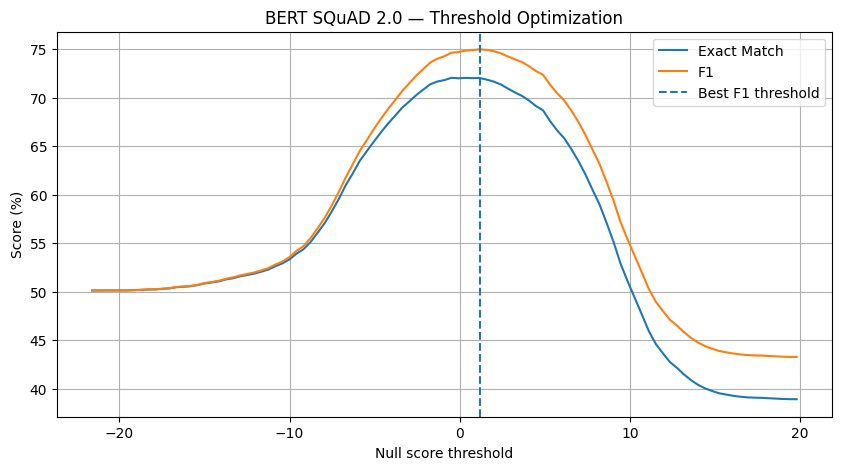

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["exact_match"],
    label="Exact Match"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Best F1 threshold"
)

plt.xlabel("Null score threshold")
plt.ylabel("Score (%)")
plt.title("BERT SQuAD 2.0 — Threshold Optimization")

plt.legend()
plt.grid(True)
plt.show()

In [27]:
print("=" * 55)
print("PRETRAINED BERT — SQUAD 2.0")
print("=" * 55)

print(
    "Parameters:",
    f"{bert_qa_model.count_params():,}"
)

print(
    "Training windows:",
    len(train_features)
)

print(
    "Validation questions:",
    len(val_df)
)

print("\n--- Threshold = 0 ---")

print(f"Exact Match: {default_em:.2f}%")
print(f"F1 Score:    {default_f1:.2f}%")

print("\n--- Best validation threshold ---")

print(
    f"Exact Match: {best_em_row['exact_match']:.2f}%"
)

print(
    f"F1 Score:    {best_f1_row['f1']:.2f}%"
)

print(
    f"Best F1 threshold: {best_threshold:.4f}"
)

PRETRAINED BERT — SQUAD 2.0
Parameters: 109,483,778
Training windows: 131754
Validation questions: 11873

--- Threshold = 0 ---
Exact Match: 72.01%
F1 Score:    74.72%

--- Best validation threshold ---
Exact Match: 72.04%
F1 Score:    74.99%
Best F1 threshold: 1.1745


In [28]:
bert_results_df["prediction"] = np.where(
    bert_results_df["score_diff"] > best_threshold,
    "",
    bert_results_df["best_span"]
)

for _, row in bert_results_df.sample(
    10,
    random_state=SEED
).iterrows():

    print("-" * 80)

    print("Question:", row["question"])

    print("Gold:", row["gold_answers"])

    print("Prediction:", row["prediction"])

    print("Score difference:", round(row["score_diff"], 3))

--------------------------------------------------------------------------------
Question: What did objects in forced motion contain according to the late Medieval idea that influence Aristotle?
Gold: ['impetus', 'innate force of impetus', 'gravity', 'an innate force of impetus', 'innate force of impetus', 'innate force of impetus']
Prediction: 
Score difference: 6.084
--------------------------------------------------------------------------------
Question: What was thought to decide a person's behavior?
Gold: ['the environment in which they lived', 'environment in which they lived', 'environment', 'the environment in which they lived', 'environment']
Prediction: the environment in which they lived
Score difference: -6.343
--------------------------------------------------------------------------------
Question: What makes the method of trial division more efficient?
Gold: ['if a complete list of primes up to  is known', 'a complete list of primes up to  is known', 'complete list of p